<a href="https://colab.research.google.com/github/iindrisw/PM-turi4-Clustering-Indri_Setiawati/blob/main/Pm_Turi4_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 9 - Clustering dengan K-Means (TuRi 4)
**Mata Kuliah:** Pembelajaran Mesin (INF62325) · **Sub-CPMK:** SCPMK0401-003  
**Nama / NIM:** Indri Setiawati/2488010077

**Tujuan:** menyiapkan data tanpa label (scaling), menentukan K dengan Elbow, menerapkan K-Means, mengevaluasi dengan silhouette score, dan menafsirkan cluster (segmentasi pelanggan).

## Langkah 0 - Membuat dataset segmentasi pelanggan (buatan)
Modul menyebut dataset buatan (usia, pendapatan, skor belanja). Dibangkitkan dari 3 kelompok dengan `seed=42` agar hasil reprodusibel. **Tidak ada kolom label.**

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rng = np.random.default_rng(42)
def grup(n, u, p, s):
    return pd.DataFrame({'usia': rng.normal(u,5,n),
                         'pendapatan': rng.normal(p,9,n),
                         'skor_belanja': rng.normal(s,8,n)})

df = pd.concat([grup(100,25,40,80), grup(100,45,90,30), grup(100,35,55,50)],
               ignore_index=True)
df['usia'] = df['usia'].clip(18,70).round()
df['pendapatan'] = df['pendapatan'].round(1)
df['skor_belanja'] = df['skor_belanja'].clip(1,100).round()
print(df.shape)
df.head()

(300, 3)


,usia,pendapatan,skor_belanja
0,27.0,36.6,83.0
1,20.0,51.7,91.0
2,29.0,36.8,81.0
3,30.0,46.6,85.0
4,18.0,31.6,64.0


In [ ]:
df.describe().round(1)

,usia,pendapatan,skor_belanja
count,300.0,300.0,300.0
mean,34.9,61.6,52.5
std,9.7,22.6,22.2
min,18.0,20.8,6.0
25%,27.0,42.6,34.0
50%,34.0,56.2,49.0
75%,43.0,84.0,74.0
max,57.0,113.4,100.0


## Langkah 1 - Menyiapkan data & scaling (wajib)
K-Means berbasis jarak, sehingga fitur berskala besar (pendapatan) akan mendominasi bila tidak disamakan skalanya. `StandardScaler` membuat tiap fitur bermean 0 dan std 1.

In [ ]:
X_scaled = StandardScaler().fit_transform(df)
print(pd.DataFrame(X_scaled, columns=df.columns).describe().loc[['mean','std']].round(2))

      usia  pendapatan  skor_belanja
mean  -0.0        -0.0           0.0
std    1.0         1.0           1.0


## Langkah 2 - Metode Elbow untuk menentukan K

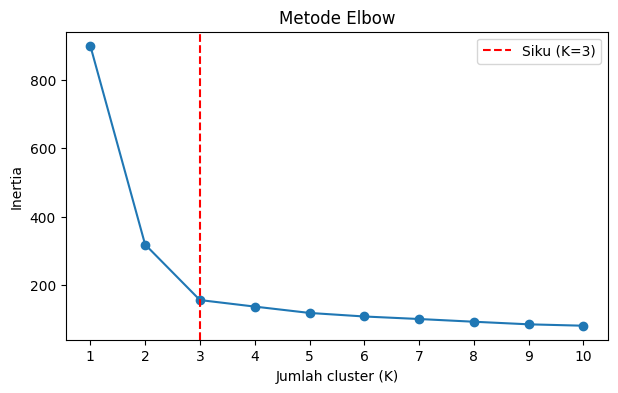

[900.0, 318.8, 156.4, 137.3, 118.7, 108.3, 101.0, 93.0, 85.4, 81.3]


In [ ]:
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)

plt.figure(figsize=(7,4))
plt.plot(range(1,11), inertias, marker='o')
plt.axvline(3, color='red', linestyle='--', label='Siku (K=3)')
plt.xlabel('Jumlah cluster (K)'); plt.ylabel('Inertia')
plt.title('Metode Elbow'); plt.legend(); plt.xticks(range(1,11)); plt.show()
print([round(i,1) for i in inertias])

**Interpretasi:** inertia turun tajam dari K=1 (≈900) ke K=2 (≈319) dan K=3 (≈156), lalu melandai (K=4 ≈137, K=5 ≈119). Titik "siku" ada di **K=3**, sehingga dipilih K=3.

## Langkah 3 - Menjalankan K-Means (K=3)

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts().sort_index())

cluster
0     99
1    102
2     99
Name: count, dtype: int64


## Langkah 4 - Evaluasi dengan silhouette score

In [ ]:
sil3 = silhouette_score(X_scaled, df['cluster'])
print('Silhouette score (K=3):', round(sil3, 4))

Silhouette score (K=3): 0.5276


**Interpretasi:** silhouette ≈ **0,53** (rentang −1 s.d. 1). Nilai > 0,5 menunjukkan cluster cukup padat dan terpisah baik, jadi K=3 layak dipakai.

## Langkah 5 - Interpretasi: profil rata-rata tiap cluster

In [ ]:
profil = df.groupby('cluster')[['usia','pendapatan','skor_belanja']].mean().round(1)
print(profil)

         usia  pendapatan  skor_belanja
cluster                                
0        45.6        89.7          29.2
1        34.4        55.5          48.8
2        24.7        39.8          79.6


In [ ]:
# Penamaan cluster berdasarkan profil (nomor cluster bisa berbeda antar-eksekusi)
nama = {
    0: 'Mapan tapi Hemat',
    1: 'Pelanggan Moderat',
    2: 'Pembelanja Muda Aktif',
}
df['segmen'] = df['cluster'].map(nama)
profil['jumlah'] = df['cluster'].value_counts().sort_index()
profil['segmen'] = profil.index.map(nama)
profil

,usia,pendapatan,skor_belanja,jumlah,segmen
cluster,,,,,
0,45.6,89.7,29.2,99,Mapan tapi Hemat
1,34.4,55.5,48.8,102,Pelanggan Moderat
2,24.7,39.8,79.6,99,Pembelanja Muda Aktif


**Penamaan cluster**

| Cluster | Usia | Pendapatan | Skor belanja | Nama segmen | Saran strategi |
|---|---|---|---|---|---|
| 0 | ≈46 | ≈90 | ≈29 | **Mapan tapi Hemat** | Daya beli tinggi tapi jarang belanja: tawarkan produk premium, program loyalitas eksklusif. |
| 1 | ≈34 | ≈56 | ≈49 | **Pelanggan Moderat** | Segmen menengah: promo bundling dan program poin untuk meningkatkan frekuensi belanja. |
| 2 | ≈25 | ≈40 | ≈80 | **Pembelanja Muda Aktif** | Muda, pendapatan rendah tetapi belanja tinggi: promo cicilan, diskon, kampanye media sosial. |

### Visualisasi cluster (pendapatan vs skor belanja)

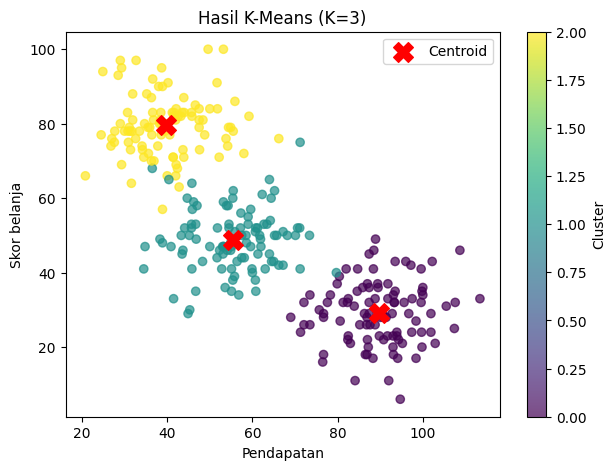

In [ ]:
plt.figure(figsize=(7,5))
sc = plt.scatter(df['pendapatan'], df['skor_belanja'], c=df['cluster'], cmap='viridis', alpha=0.7)
cen = pd.DataFrame(StandardScaler().fit(df[['usia','pendapatan','skor_belanja']]).inverse_transform(kmeans.cluster_centers_),
                   columns=['usia','pendapatan','skor_belanja'])
plt.scatter(cen['pendapatan'], cen['skor_belanja'], c='red', marker='X', s=200, label='Centroid')
plt.xlabel('Pendapatan'); plt.ylabel('Skor belanja'); plt.title('Hasil K-Means (K=3)')
plt.legend(); plt.colorbar(sc, label='Cluster'); plt.show()

## D. Latihan Mandiri

### Latihan 1 - K=5 vs K=3

In [ ]:
km5 = KMeans(n_clusters=5, random_state=42, n_init=10)
lab5 = km5.fit_predict(X_scaled)
sil5 = silhouette_score(X_scaled, lab5)
print(f'Silhouette K=3: {sil3:.4f}')
print(f'Silhouette K=5: {sil5:.4f}')

Silhouette K=3: 0.5276
Silhouette K=5: 0.3615


**Jawaban:** silhouette K=5 (≈0,36) lebih rendah daripada K=3 (≈0,53). Data sebenarnya hanya memiliki 3 kelompok alami, sehingga K=5 memecah kelompok yang sudah padat dan membuat cluster saling berdekatan/tumpang tindih. K=3 lebih tepat.

### Latihan 2 - K-Means tanpa scaling (K=3)

In [ ]:
fitur = df[['usia','pendapatan','skor_belanja']]
lab_ns = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(fitur)

print('Silhouette tanpa scaling (ruang asli)      :', round(silhouette_score(fitur, lab_ns), 4))
print('Silhouette tanpa scaling (dinilai di ruang ter-scale):', round(silhouette_score(X_scaled, lab_ns), 4))
print('Silhouette dengan scaling                  :', round(sil3, 4))
print()
print('Perbandingan label (baris = dengan scaling, kolom = tanpa scaling):')
print(pd.crosstab(df['cluster'], lab_ns))
print()
print('Std fitur asli   :', fitur.std().round(1).to_dict())

Silhouette tanpa scaling (ruang asli)      : 0.5599
Silhouette tanpa scaling (dinilai di ruang ter-scale): 0.5233
Silhouette dengan scaling                  : 0.5276

Perbandingan label (baris = dengan scaling, kolom = tanpa scaling):
col_0     0   1   2
cluster            
0        99   0   0
1         1  99   2
2         0   1  98

Std fitur asli   : {'usia': 9.7, 'pendapatan': 22.6, 'skor_belanja': 22.2}


**Jawaban & kesimpulan:**
- Silhouette tanpa scaling dihitung di ruang asli (≈0,56) **tidak sebanding** dengan versi ter-scale, karena jarak didominasi `pendapatan` (std ≈ 22) dibanding `usia` (≈ 10) dan `skor_belanja` (≈ 22). Skor yang lebih tinggi di sini menyesatkan.
- Bila hasilnya dinilai pada ruang yang adil (ter-scale), skornya ≈0,52, sedikit di bawah versi dengan scaling (≈0,53).
- Pada dataset ini perbedaan label kecil karena ketiga fitur kebetulan berskala mirip dan kelompoknya sangat terpisah. **Pada data nyata dengan skala timpang** (misal pendapatan dalam jutaan rupiah vs usia puluhan), K-Means tanpa scaling akan hampir hanya memakai fitur terbesar.
- **Kesimpulan:** scaling wajib pada K-Means agar setiap fitur berkontribusi setara dan evaluasi dapat dibandingkan.


### Latihan 3 - Scatter plot usia (x) vs skor_belanja (y)

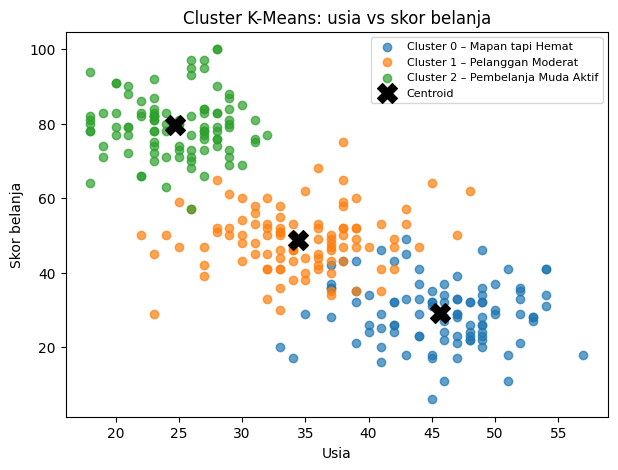

In [ ]:
plt.figure(figsize=(7,5))
for c in sorted(df['cluster'].unique()):
    s = df[df['cluster']==c]
    plt.scatter(s['usia'], s['skor_belanja'], alpha=0.7, label=f'Cluster {c} – {nama[c]}')
plt.scatter(cen['usia'], cen['skor_belanja'], c='black', marker='X', s=200, label='Centroid')
plt.xlabel('Usia'); plt.ylabel('Skor belanja')
plt.title('Cluster K-Means: usia vs skor belanja'); plt.legend(fontsize=8); plt.show()

**Pengamatan:** semakin muda usia, skor belanja cenderung makin tinggi. Ketiga cluster tampak terpisah jelas sepanjang diagonal usia–skor belanja.

## E. Refleksi

**1. Bagaimana K-Means menemukan kelompok tanpa label?**  
K-Means hanya memakai kemiripan (jarak) antar titik. Ia menempatkan K centroid awal secara acak, lalu mengulang: (1) tiap titik dimasukkan ke centroid terdekat, (2) centroid dipindah ke rata-rata anggotanya. Proses berhenti saat centroid tak lagi bergeser (konvergen). Karena tujuannya meminimalkan jarak titik ke centroid, kelompok terbentuk dari struktur data itu sendiri tanpa perlu label.

**2. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?**  
Data dibangkitkan dari 3 kelompok alami. Menambah cluster dari 1 ke 3 memecah kelompok nyata sehingga inertia turun drastis (≈900 → ≈156). Setelah K=3, cluster tambahan hanya memecah kelompok yang sudah padat sehingga penurunannya kecil dan grafik melandai, membentuk siku di K=3.

**3. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?**  
K-Means memakai jarak Euclidean. Fitur berskala besar mendominasi jarak, sedangkan fitur berskala kecil nyaris diabaikan. Tanpa scaling, cluster menjadi bias ke fitur terbesar, tidak mencerminkan semua fitur, dan silhouette yang dihitung tidak dapat dibandingkan secara adil.